# DATA PREPROCESSING AND MODEL TRAINING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv("D:/Project 4 - Global Mobile Reviews/Mobile Recommendation/cleaned_data.csv")
print(df.shape)

(47432, 18)


## Encoding

In [2]:
# Label encoding
df["Brand_code"] = df["Brand"].astype("category").cat.codes
df["Model_code"] = df["Model"].astype("category").cat.codes
df["Country_code"] = df["Country"].astype("category").cat.codes

# One-hot encoding
brand_dummies = pd.get_dummies(df["Brand"], prefix="Brand", dtype=int)
country_dummies = pd.get_dummies(df["Country"], prefix="Country", dtype=int)
df_encoded = pd.concat([df, brand_dummies, country_dummies], axis=1)

print("Rows:", df_encoded.shape[0], "| Columns:", df_encoded.shape[1], "| Null values:", df_encoded.isnull().sum().sum())
df_encoded.head()

Rows: 47432 | Columns: 36 | Null values: 0


,Customer_age,Brand,Model,Source,Country,Currency,Exchange_rate_to_usd,Price_local,Price_usd,Verified_purchase,...,Brand_Samsung,Brand_Xiaomi,Country_Australia,Country_Brazil,Country_Canada,Country_Germany,Country_India,Country_UAE,Country_UK,Country_USA
0,45,Realme,Realme 12 Pro,Amazon,India,INR,83.00,27996.73,337.31,1,...,0,0,0,0,0,0,1,0,0,0
1,18,Realme,Realme 12 Pro,Flipkart,Brazil,BRL,5.70,1754.35,307.78,1,...,0,0,0,1,0,0,0,0,0,0
2,27,Google,Pixel 6,AliExpress,India,INR,83.00,71755.99,864.53,1,...,0,0,0,0,0,0,1,0,0,0
3,19,Xiaomi,Redmi Note 13,Amazon,UAE,AED,3.67,2425.65,660.94,0,...,0,1,0,0,0,0,0,1,0,0
4,38,Motorola,Edge 50,BestBuy,Brazil,BRL,5.70,4515.14,792.13,1,...,0,0,0,1,0,0,0,0,0,0


In [3]:
df_encoded.to_csv("encoded_data.csv", index=False)
df = df_encoded

## Feature selection
***Features :***  Price_usd, Rating and the 5 part-ratings (battery, camera, performance, design, display).

Brand, model and country are used only as names. All models of a brand cost about the same, so brand adds nothing beyond price, and every model has reviews from all countries in a similar amount.

In [4]:
df.groupby("Brand")["Price_usd"].agg(["min", "mean", "max"]).round(2)

,min,mean,max
Brand,,,
Apple,700.01,1103.71,1499.82
Google,500.05,804.79,1099.98
Motorola,200.01,506.61,799.99
OnePlus,350.01,673.11,999.90
Realme,180.07,393.23,599.94
Samsung,400.71,900.25,1399.70
Xiaomi,200.17,449.75,699.96


## Product table

In [5]:
features = ["Price_usd", "Rating", "Battery_life_rating", "Camera_rating",
            "Performance_rating", "Design_rating", "Display_rating"]

products = df.groupby(["Brand", "Model"])[features].mean().reset_index()
products["Reviews"] = df.groupby(["Brand", "Model"]).size().values

products.sort_values("Price_usd")

,Brand,Model,Price_usd,Rating,Battery_life_rating,Camera_rating,Performance_rating,Design_rating,Display_rating,Reviews
14,Realme,Realme Narzo 70,392.525203,3.126719,2.730465,2.731051,2.743927,2.704419,2.733685,3417
13,Realme,Realme 12 Pro,393.947397,3.145492,2.721809,2.708420,2.763166,2.736983,2.759595,3361
19,Xiaomi,Mi 13 Pro,448.674548,3.099398,2.707831,2.711274,2.670396,2.666523,2.707831,2324
20,Xiaomi,Poco X6,450.183792,3.129283,2.718136,2.740521,2.770215,2.766103,2.722704,2189
21,Xiaomi,Redmi Note 13,450.412169,3.118477,2.713858,2.714713,2.710009,2.699743,2.689906,2338
8,Motorola,Moto G Power,504.940598,3.127289,2.709692,2.700313,2.702099,2.705226,2.712372,2239
9,Motorola,Razr 40,506.891372,3.109703,2.709353,2.677010,2.725524,2.720717,2.721591,2288
7,Motorola,Edge 50,508.035973,3.090909,2.677227,2.700643,2.707989,2.683655,2.720386,2178
11,OnePlus,OnePlus 12,671.563376,3.137210,2.732849,2.752385,2.726942,2.727851,2.717856,2201
10,OnePlus,OnePlus 11R,672.598906,3.117571,2.701550,2.701981,2.712748,2.696813,2.714470,2322


## Scaling
Price is scaled on its real range and ratings on the 1 to 5 scale, so every feature is between 0 and 1.

In [16]:
price_min = df["Price_usd"].min()
price_max = df["Price_usd"].max()

X = products[features].copy()
X["Price_usd"] = (X["Price_usd"] - price_min) / (price_max - price_min)
for col in features[1:]:
    X[col] = (X[col] - 1) / 4

X

,Price_usd,Rating,Battery_life_rating,Camera_rating,Performance_rating,Design_rating,Display_rating
0,0.702903,0.539654,0.440072,0.440668,0.443948,0.444842,0.427698
1,0.696432,0.546384,0.438945,0.447244,0.435388,0.446206,0.441168
2,0.701079,0.521475,0.417210,0.428614,0.413211,0.421060,0.423134
3,0.699056,0.525806,0.432698,0.425367,0.431085,0.421848,0.430499
4,0.475900,0.529589,0.429656,0.428205,0.423180,0.426418,0.428986
5,0.475123,0.532106,0.428831,0.433005,0.430758,0.429902,0.437928
6,0.469030,0.532561,0.436203,0.430132,0.425055,0.437307,0.436865
7,0.248506,0.522727,0.419307,0.425161,0.426997,0.420914,0.430096
8,0.246161,0.531822,0.427423,0.425078,0.425525,0.426306,0.428093
9,0.247639,0.527426,0.427338,0.419253,0.431381,0.430179,0.430398


## Number of clusters

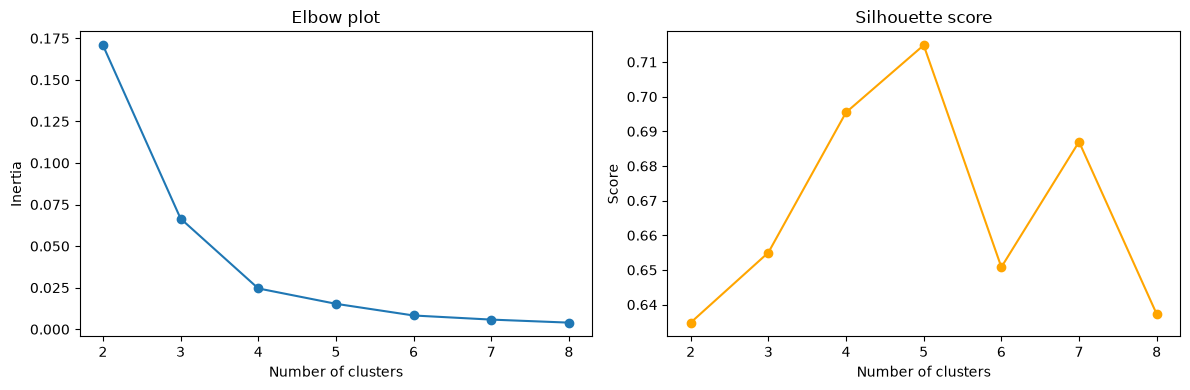

   k  Inertia  Silhouette
0  2    0.171       0.635
1  3    0.067       0.655
2  4    0.025       0.695
3  5    0.015       0.715
4  6    0.008       0.651
5  7    0.006       0.687
6  8    0.004       0.637


In [7]:
k_values = [2, 3, 4, 5, 6, 7, 8]
inertia_list = []
silhouette_list = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X, labels))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_list, marker="o")
plt.title("Elbow plot")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_list, marker="o", color="orange")
plt.title("Silhouette score")
plt.xlabel("Number of clusters")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

print(pd.DataFrame({"k": k_values, "Inertia": np.round(inertia_list, 3), "Silhouette": np.round(silhouette_list, 3)}))

4 clusters: the elbow bends at 4 and the silhouette score is 0.695.

## K-Means with 4 clusters

In [8]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
products["Cluster"] = kmeans.fit_predict(X)

names = ["Budget", "Mid-range", "Upper mid-range", "Premium"]
cluster_prices = products.groupby("Cluster")["Price_usd"].mean().sort_values()

segment_names = {}
i = 0
for cluster in cluster_prices.index:
    segment_names[cluster] = names[i]
    i = i + 1

products["Segment"] = products["Cluster"].map(segment_names)

products[["Segment", "Brand", "Model", "Price_usd", "Rating"]].sort_values("Price_usd")

,Segment,Brand,Model,Price_usd,Rating
14,Budget,Realme,Realme Narzo 70,392.525203,3.126719
13,Budget,Realme,Realme 12 Pro,393.947397,3.145492
19,Budget,Xiaomi,Mi 13 Pro,448.674548,3.099398
20,Budget,Xiaomi,Poco X6,450.183792,3.129283
21,Budget,Xiaomi,Redmi Note 13,450.412169,3.118477
8,Budget,Motorola,Moto G Power,504.940598,3.127289
9,Budget,Motorola,Razr 40,506.891372,3.109703
7,Budget,Motorola,Edge 50,508.035973,3.090909
11,Mid-range,OnePlus,OnePlus 12,671.563376,3.137210
10,Mid-range,OnePlus,OnePlus 11R,672.598906,3.117571


In [17]:
products

,Brand,Model,Price_usd,Rating,Battery_life_rating,Camera_rating,Performance_rating,Design_rating,Display_rating,Reviews,Cluster,Segment
0,Apple,iPhone 13,1107.725909,3.158617,2.760286,2.762671,2.775790,2.779368,2.710793,1677,2,Premium
1,Apple,iPhone 14,1099.185910,3.185536,2.755779,2.788975,2.741553,2.784825,2.764671,1687,2,Premium
2,Apple,iPhone 15 Pro,1105.318377,3.085900,2.668839,2.714455,2.652844,2.684242,2.692536,1688,2,Premium
3,Apple,iPhone SE,1102.648974,3.103226,2.730792,2.701466,2.724340,2.687390,2.721994,1705,2,Premium
4,Google,Pixel 6,808.139116,3.118356,2.718624,2.712818,2.692720,2.705672,2.715945,2239,1,Upper mid-range
5,Google,Pixel 7a,807.113900,3.128425,2.715325,2.732021,2.723031,2.719606,2.751712,2336,1,Upper mid-range
6,Google,Pixel 8,799.072106,3.130243,2.744812,2.720530,2.700221,2.749227,2.747461,2265,1,Upper mid-range
7,Motorola,Edge 50,508.035973,3.090909,2.677227,2.700643,2.707989,2.683655,2.720386,2178,0,Budget
8,Motorola,Moto G Power,504.940598,3.127289,2.709692,2.700313,2.702099,2.705226,2.712372,2239,0,Budget
9,Motorola,Razr 40,506.891372,3.109703,2.709353,2.677010,2.725524,2.720717,2.721591,2288,0,Budget


## Understanding the segments

In [9]:
summary = products.groupby("Segment").agg({"Model": "count", "Reviews": "sum",
                                           "Price_usd": "mean", "Rating": "mean"})
summary = summary.reindex(names).round(2)
summary["Share_of_reviews_%"] = (summary["Reviews"] / summary["Reviews"].sum() * 100).round(1)
print(summary)
print()

for seg in names:
    brands = products[products["Segment"] == seg]["Brand"].unique()
    print(seg, "->", list(brands))

                 Model  Reviews  Price_usd  Rating  Share_of_reviews_%
Segment                                                               
Budget               8    20334     456.95    3.12                42.9
Mid-range            3     6791     673.10    3.13                14.3
Upper mid-range      7    13550     859.31    3.12                28.6
Premium              4     6757    1103.72    3.13                14.2

Budget -> ['Motorola', 'Realme', 'Xiaomi']
Mid-range -> ['OnePlus']
Upper mid-range -> ['Google', 'Samsung']
Premium -> ['Apple']


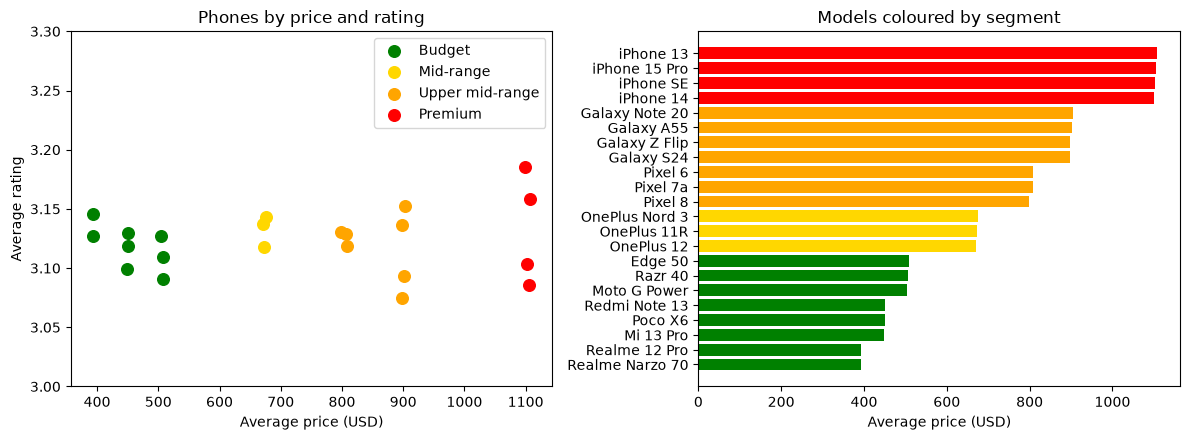

In [10]:
colors = {"Budget": "green", "Mid-range": "gold", "Upper mid-range": "orange", "Premium": "red"}

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
for seg in names:
    part = products[products["Segment"] == seg]
    plt.scatter(part["Price_usd"], part["Rating"], label=seg, color=colors[seg], s=70)
plt.xlabel("Average price (USD)")
plt.ylabel("Average rating")
plt.ylim(3.0, 3.3)
plt.title("Phones by price and rating")
plt.legend()

plt.subplot(1, 2, 2)
sorted_products = products.sort_values("Price_usd")
plt.barh(sorted_products["Model"], sorted_products["Price_usd"],
         color=[colors[s] for s in sorted_products["Segment"]])
plt.xlabel("Average price (USD)")
plt.title("Models coloured by segment")

plt.tight_layout()
plt.show()

- **Budget:** Realme, Xiaomi and Motorola (8 phones, about 43% of reviews).
- **Mid-range:** OnePlus.
- **Upper mid-range:** Google and Samsung.
- **Premium:** Apple.
- The segments are price groups. Ratings are almost the same in every segment (about 3.12 to 3.13).

## Recommendation system

In [11]:
similarity = cosine_similarity(X)


def recommend_similar(model_name, top_n=5, same_segment_only=False):
    row = products[products["Model"] == model_name].index[0]

    result = products[["Brand", "Model", "Segment", "Price_usd", "Rating"]].copy()
    result["Similarity"] = similarity[row]
    result = result.drop(row)

    if same_segment_only:
        result = result[result["Segment"] == products.loc[row, "Segment"]]

    result = result.sort_values("Similarity", ascending=False).head(top_n)
    result["Price_usd"] = result["Price_usd"].round(2)
    result["Rating"] = result["Rating"].round(2)
    result["Similarity"] = result["Similarity"].round(4)
    return result.reset_index(drop=True)


def recommend_by_budget(budget, min_rating=1.0, priority="Rating", brand="All", top_n=5):
    result = products[products["Price_usd"] <= budget]
    result = result[result["Rating"] >= min_rating]

    if brand != "All":
        result = result[result["Brand"] == brand]

    result = result.sort_values(priority, ascending=False)

    columns = ["Brand", "Model", "Segment", "Price_usd", "Rating"]
    if priority != "Rating":
        columns.append(priority)

    return result[columns].head(top_n).round(2).reset_index(drop=True)

In [12]:
print(recommend_similar("iPhone 13"))
print()
print(recommend_similar("Galaxy S24", same_segment_only=True))
print()
print(recommend_by_budget(700, min_rating=3.1, priority="Camera_rating"))

     Brand          Model          Segment  Price_usd  Rating  Similarity
0    Apple      iPhone 14          Premium    1099.19    3.19      0.9999
1    Apple      iPhone SE          Premium    1102.65    3.10      0.9999
2    Apple  iPhone 15 Pro          Premium    1105.32    3.09      0.9997
3  Samsung     Galaxy S24  Upper mid-range     897.36    3.07      0.9959
4  Samsung     Galaxy A55  Upper mid-range     901.65    3.09      0.9959

     Brand           Model          Segment  Price_usd  Rating  Similarity
0  Samsung      Galaxy A55  Upper mid-range     901.65    3.09      0.9999
1  Samsung  Galaxy Note 20  Upper mid-range     903.69    3.15      0.9999
2  Samsung   Galaxy Z Flip  Upper mid-range     898.13    3.14      0.9998
3   Google         Pixel 6  Upper mid-range     808.14    3.12      0.9982
4   Google        Pixel 7a  Upper mid-range     807.11    3.13      0.9979

     Brand            Model    Segment  Price_usd  Rating  Camera_rating
0  OnePlus       OnePlus 12  Mi

## Local currency
Every country has one currency and one exchange rate, so the local price is the USD price multiplied by the rate.

In [13]:
country_info = df.groupby("Country")[["Currency", "Exchange_rate_to_usd"]].first()
print(country_info)


def add_local_price(result, country):
    currency = country_info.loc[country, "Currency"]
    rate = country_info.loc[country, "Exchange_rate_to_usd"]
    result["Price_" + currency] = (result["Price_usd"] * rate).round(2)
    return result


add_local_price(recommend_similar("iPhone 13", top_n=3), "India")

          Currency  Exchange_rate_to_usd
Country                                 
Australia      AUD                  1.53
Brazil         BRL                  5.70
Canada         CAD                  1.38
Germany        EUR                  0.93
India          INR                 83.00
UAE            AED                  3.67
UK             GBP                  0.78
USA            USD                  1.00


,Brand,Model,Segment,Price_usd,Rating,Similarity,Price_INR
0,Apple,iPhone 14,Premium,1099.19,3.19,0.9999,91232.77
1,Apple,iPhone SE,Premium,1102.65,3.10,0.9999,91519.95
2,Apple,iPhone 15 Pro,Premium,1105.32,3.09,0.9997,91741.56


## Checking the recommendations
For every phone, the top 3 recommendations are compared with random recommendations:
- **Price gap:** how far (in dollars) the recommended phones are from the chosen phone.
- **Same segment:** how many recommendations are in the same segment.

In [14]:
gaps = []
same = []
for i in range(len(products)):
    scores = similarity[i].copy()
    scores[i] = -10
    best = scores.argsort()[::-1][:3]
    for j in best:
        gaps.append(abs(products.loc[j, "Price_usd"] - products.loc[i, "Price_usd"]))
        same.append(products.loc[j, "Segment"] == products.loc[i, "Segment"])

random_gaps = []
random_same = []
for i in range(len(products)):
    for j in range(len(products)):
        if i != j:
            random_gaps.append(abs(products.loc[j, "Price_usd"] - products.loc[i, "Price_usd"]))
            random_same.append(products.loc[j, "Segment"] == products.loc[i, "Segment"])

results = pd.DataFrame({
    "Method": ["Our system", "Random"],
    "Avg price gap ($)": [round(np.mean(gaps), 1), round(np.mean(random_gaps), 1)],
    "Same segment (%)": [round(np.mean(same) * 100, 1), round(np.mean(random_same) * 100, 1)]})
results

,Method,Avg price gap ($),Same segment (%)
0,Our system,21.3,95.5
1,Random,290.5,25.1


Recommended phones are about $21 away in price from the chosen phone (random: about $290), and about 95% are in the same segment (random: about 25%). Ratings barely differ between phones, so similarity is mostly price-based.

In [15]:
products.to_csv("model_level_clusters.csv", index=False)